# Strategy research: can the Q5 volatility-targeted book be improved?

Companion to `leverage_effect.ipynb`. Five hypotheses, written down in `docs/STRATEGY_RESEARCH.md` (Part 1) and committed **before** any variant was run, are tested against the HAR baseline with the same walk-forward design, costs, band, 1995 start and bootstrap. Every hypothesis is reported, winners and losers, and the results are corrected for multiple testing (Holm, Deflated Sharpe Ratio).

All strategy code lives in `src/strategy.py`; this notebook only runs and reports it. Pre-registered adoption rule for a "v2": Holm-adjusted p < 0.05, DSR (N = 40) >= 0.95, higher Sharpe than the baseline in both sub-periods and at doubled costs, max drawdown no more than 2 points worse.

In [1]:
import sys
sys.path.insert(0, "../src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import strategy as S
from scipy.stats import norm

pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.figsize": (13, 4), "axes.grid": True, "grid.alpha": 0.3})

study = S.Study("../data")

## 0. The baseline must reproduce before anything is tested

`check_baseline` rebuilds all 11 rows of the README Q5 table (return, vol, Sharpe, max drawdown) from the raw files and asserts an exact match at the printed precision. (One correction: the README printed ALL HAR-trend vol as 3.17; the unrounded value is 3.1645, shown as 3.165 in the original notebook, so it is 3.16. The README is fixed.) Turnover and bootstrap p-values are checked against the original notebook's stored output too.

In [2]:
check = S.check_baseline(study)
display(check)

baseline_all = S.baseline_books(study)
har_frames = study.frames("HAR", "HAR")
books, held = S.backtest(har_frames)
assert round(S.turnover(held["ALL"]), 3) == 2.582                      # original notebook output, ALL HAR
assert round(S.sharpe_p_value(S.baseline_books(study)[("ALL", "HAR-trend")], books["ALL"]), 2) == 0.86   # ALL HAR-trend vs HAR
print("baseline reproduced: 11/11 README rows, turnover and bootstrap p match the original notebook")

,book,strategy,readme,reproduced,match
0,EQ,Trailing vol,"(1.58, 7.74, 0.205, -44.5)","(1.58, 7.74, 0.205, -44.5)",True
1,EQ,HAR,"(1.5, 6.62, 0.227, -43.0)","(1.5, 6.62, 0.227, -43.0)",True
2,EQ,HAR-lev,"(1.27, 6.69, 0.19, -44.7)","(1.27, 6.69, 0.19, -44.7)",True
3,EQ,HAR-trend,"(1.43, 4.0, 0.357, -13.1)","(1.43, 4.0, 0.357, -13.1)",True
4,BD,Trailing vol,"(6.35, 7.4, 0.859, -19.3)","(6.35, 7.4, 0.859, -19.3)",True
5,BD,HAR,"(6.62, 7.14, 0.926, -20.0)","(6.62, 7.14, 0.926, -20.0)",True
6,BD,HAR-trend,"(4.85, 5.32, 0.911, -11.6)","(4.85, 5.32, 0.911, -11.6)",True
7,ALL,Trailing vol,"(4.14, 4.52, 0.916, -14.9)","(4.14, 4.52, 0.916, -14.9)",True
8,ALL,HAR,"(4.28, 4.2, 1.018, -11.0)","(4.28, 4.2, 1.018, -11.0)",True
9,ALL,HAR-lev,"(4.18, 4.23, 0.99, -10.6)","(4.18, 4.23, 0.99, -10.6)",True


baseline reproduced: 11/11 README rows, turnover and bootstrap p match the original notebook


## 1. Build the five pre-registered variants

Each variant changes only the position sizes (`w`) or the forecast behind them; features, walk-forward refitting, band, trade timing and costs are the baseline's. H3 also returns the walk-forward correction coefficients so they can be inspected.

In [3]:
h3_frames, h3_coef = S.h3_bias_corrected(study, har_frames)
VARIANTS = {
    "HAR (baseline)": har_frames,
    "H1 sleeve risk parity": S.h1_sleeve_risk_parity(study, har_frames),
    "H2 variance-managed": S.h2_variance_managed(study, har_frames),
    "H3 bias-corrected HAR": h3_frames,
    "H4 ensemble HAR/HAR-lev": S.h4_ensemble(study, har_frames),
    "H5 asymmetric min(HAR, HAR-lev)": S.h5_asymmetric(study, har_frames),
}
BASE = "HAR (baseline)"
RUNS = {1.0: {}, 2.0: {}}
for mult in RUNS:
    for name, frames in VARIANTS.items():
        RUNS[mult][name] = S.backtest(frames, cost_mult=mult)

def all_pnl(name, mult=1.0):
    return RUNS[mult][name][0]["ALL"]

# the ALL baseline must equal the one reproduced above
assert np.allclose(all_pnl(BASE).values, baseline_all[("ALL", "HAR")].values, equal_nan=True)

## 2. Primary result: ALL book, net of costs, 1995-2017

`p vs HAR` is the notebook's 21-day block bootstrap (1000 resamples) of the Sharpe gap. `p Holm` adjusts the five p-values step-down. `DSR` is the Deflated Sharpe Ratio of the variant's own daily P&L (probability its true Sharpe exceeds the best-of-N luck benchmark) with N = 40 trials, N = 6 and N = 100 as sensitivity; the cross-trial Sharpe variance comes from the six strategies here.

In [4]:
N_TRIALS = 40
daily_sr = pd.Series({n: all_pnl(n).mean() / all_pnl(n).std() for n in VARIANTS})
sr_var = daily_sr.var(ddof=1)
print(f"cross-trial variance of daily Sharpe: {sr_var:.3e}  (annualised-Sharpe sd across the 6 = {daily_sr.std(ddof=1) * np.sqrt(252):.3f})")

rows = {}
for name in VARIANTS:
    pnl = all_pnl(name)
    held_all = RUNS[1.0][name][1]["ALL"]
    rows[name] = {**S.perf(pnl, held_all),
                  "p_vs_HAR": np.nan if name == BASE else S.sharpe_p_value(pnl, all_pnl(BASE))}
res = pd.DataFrame(rows).T
hyp = [n for n in VARIANTS if n != BASE]
res.loc[hyp, "p_holm"] = pd.Series(S.holm(res.loc[hyp, "p_vs_HAR"].to_dict()))
for n_trials in (N_TRIALS, 6, 100):
    res[f"DSR_N{n_trials}"] = [S.deflated_sharpe(all_pnl(n), n_trials, sr_var) for n in VARIANTS]
res.loc[:, "SR0_ann_N40"] = np.sqrt(252) * np.sqrt(sr_var) * (
    (1 - 0.5772156649015329) * norm.ppf(1 - 1 / 40) + 0.5772156649015329 * norm.ppf(1 - 1 / (40 * np.e)))
res

cross-trial variance of daily Sharpe: 4.145e-06  (annualised-Sharpe sd across the 6 = 0.032)


,ann_ret_pct,ann_vol_pct,sharpe,max_dd_pct,vol_of_vol_pct,turnover,p_vs_HAR,p_holm,DSR_N40,DSR_N6,DSR_N100,SR0_ann_N40
HAR (baseline),4.277,4.201,1.018,-10.972,0.977,2.582,NaN,NaN,1.0,1.0,1.0,0.071
H1 sleeve risk parity,3.607,3.888,0.928,-12.597,0.713,4.514,0.076,0.304,1.0,1.0,1.0,0.071
H2 variance-managed,5.288,5.267,1.004,-12.352,1.502,13.224,0.857,0.857,1.0,1.0,1.0,0.071
H3 bias-corrected HAR,4.227,4.312,0.980,-11.570,0.962,3.393,0.083,0.304,1.0,1.0,1.0,0.071
H4 ensemble HAR/HAR-lev,4.239,4.210,1.007,-10.816,0.985,3.096,0.305,0.610,1.0,1.0,1.0,0.071
"H5 asymmetric min(HAR, HAR-lev)",4.262,4.287,0.994,-11.081,1.004,2.773,0.031,0.155,1.0,1.0,1.0,0.071


The DSR column is 1.000 for every row, the baseline included: with ~6000 daily observations an annual Sharpe near 1 is far above the best-of-N benchmark `SR0` (last column, in annualised units) implied by the small spread of Sharpe ratios across these six strategies. So the pre-registered DSR criterion is passed trivially and does not discriminate; it says each strategy has a positive Sharpe after selection, not that it beats HAR. The decision therefore rests on the bootstrap, Holm and robustness criteria below.

**How sensitive is the DSR to the cross-trial variance?** `V` above comes from the six strategies of this study only, which are all close variants of HAR. The ~34 earlier configurations recorded in `NOTES.md` were more dispersed (their ALL Sharpe ratios range from about 0.3 to 1.2, but those runs are indicative, not exact), so `V` is likely understated. The table recomputes the baseline's DSR for an assumed sd of annualised Sharpe across trials.

In [5]:
dsr_sens = pd.DataFrame({
    sd: {f"DSR N={n}": S.deflated_sharpe(all_pnl(BASE), n, (sd / np.sqrt(252)) ** 2) for n in (6, N_TRIALS, 100)}
    for sd in (0.032, 0.1, 0.2, 0.3, 0.4)}).T.rename_axis("sd of annualised Sharpe across trials")
dsr_sens

,DSR N=6,DSR N=40,DSR N=100
sd of annualised Sharpe across trials,,,
0.032,1.000,1.000,1.000
0.100,1.000,1.000,1.000
0.200,1.000,0.997,0.993
0.300,0.999,0.958,0.893
0.400,0.992,0.752,0.511


## 3. Robustness: sub-periods and doubled costs

In [6]:
SUBS = {"1995-2006": ("1995", "2006"), "2007-2017": ("2007", "2017")}
rob = {}
for name in VARIANTS:
    rob[name] = {f"Sharpe {k}": S.subperiod_sharpe(all_pnl(name), *v) for k, v in SUBS.items()}
    p2 = all_pnl(name, 2.0)
    rob[name].update({"Sharpe cost x2": S.sharpe(p2), "ret % cost x2": 100 * 252 * p2.mean(), "max DD % cost x2": 100 * S.max_drawdown(p2)})
rob = pd.DataFrame(rob).T
rob

,Sharpe 1995-2006,Sharpe 2007-2017,Sharpe cost x2,ret % cost x2,max DD % cost x2
HAR (baseline),1.045,0.992,1.014,4.261,-10.989
H1 sleeve risk parity,0.904,0.954,0.921,3.581,-12.627
H2 variance-managed,1.102,0.883,0.989,5.210,-12.533
H3 bias-corrected HAR,1.004,0.958,0.975,4.204,-11.623
H4 ensemble HAR/HAR-lev,1.037,0.976,1.002,4.219,-10.838
"H5 asymmetric min(HAR, HAR-lev)",1.017,0.973,0.990,4.244,-11.099


## 4. Pre-registered adoption rule, applied mechanically

In [7]:
crit = pd.DataFrame(index=hyp)
crit["Holm p < 0.05"] = res.loc[hyp, "p_holm"] < 0.05
crit["DSR(N=40) >= 0.95"] = res.loc[hyp, f"DSR_N{N_TRIALS}"] >= 0.95
crit["better in 1995-2006"] = rob.loc[hyp, "Sharpe 1995-2006"] > rob.loc[BASE, "Sharpe 1995-2006"]
crit["better in 2007-2017"] = rob.loc[hyp, "Sharpe 2007-2017"] > rob.loc[BASE, "Sharpe 2007-2017"]
crit["better at cost x2"] = rob.loc[hyp, "Sharpe cost x2"] > rob.loc[BASE, "Sharpe cost x2"]
crit["max DD not >2pp worse"] = res.loc[hyp, "max_dd_pct"] >= res.loc[BASE, "max_dd_pct"] - 2
crit["ADOPT as v2"] = crit.all(axis=1)
crit

,Holm p < 0.05,DSR(N=40) >= 0.95,better in 1995-2006,better in 2007-2017,better at cost x2,max DD not >2pp worse,ADOPT as v2
H1 sleeve risk parity,False,True,False,False,False,True,False
H2 variance-managed,False,True,True,False,False,True,False
H3 bias-corrected HAR,False,True,False,False,False,True,False
H4 ensemble HAR/HAR-lev,False,True,False,False,False,True,False
"H5 asymmetric min(HAR, HAR-lev)",False,True,False,False,False,True,False


## 5. Equity and bond books separately

Context for where each variant acts (not part of the decision rule). H1 is defined for the ALL book only; H4 and H5 leave bonds on HAR, so their BD book equals the baseline's.

In [8]:
parts = {}
for name in VARIANTS:
    bk, hd = RUNS[1.0][name]
    for cat in ("EQ", "BD"):
        if name.startswith("H1"):
            continue
        parts[(cat, name)] = {**S.perf(bk[cat], hd[cat]),
                              "p_vs_HAR": np.nan if name == BASE else S.sharpe_p_value(bk[cat], RUNS[1.0][BASE][0][cat])}
pd.DataFrame(parts).T.sort_index(level=0, sort_remaining=False)

ann_ret_pct  ann_vol_pct  sharpe  \
BD HAR (baseline)                         6.617        7.144   0.926   
   H2 variance-managed                    8.020        9.149   0.877   
   H3 bias-corrected HAR                  6.631        7.191   0.922   
   H4 ensemble HAR/HAR-lev                6.617        7.144   0.926   
   H5 asymmetric min(HAR, HAR-lev)        6.617        7.144   0.926   
EQ HAR (baseline)                         1.504        6.616   0.227   
   H2 variance-managed                    1.992        7.415   0.269   
   H3 bias-corrected HAR                  1.372        6.943   0.198   
   H4 ensemble HAR/HAR-lev                1.414        6.638   0.213   
   H5 asymmetric min(HAR, HAR-lev)        1.464        6.930   0.211   

                                    max_dd_pct  vol_of_vol_pct  turnover  \
BD HAR (baseline)                      -20.028           1.028     3.895   
   H2 variance-managed                 -34.202           2.004    20.240   
   H3 bias-corrected HAR               -20.513           1.101     3.526   
   H4 ensemble HAR/HAR-lev             -20.028           1.028     3.895   
   H5 asymmetric min(HAR, HAR-lev)     -20.028           1.028     3.895   
EQ HAR (baseline)                      -42.965           1.509     1.269   
   H2 variance-managed                 -40.176           2.438     6.208   
   H3 bias-corrected HAR               -48.112           1.275     3.261   
   H4 ensemble HAR/HAR-lev             -43.466           1.449     2.296   
   H5 asymmetric min(HAR, HAR-lev)     -45.304           1.516     1.651   

                                    p_vs_HAR  
BD HAR (baseline)                        NaN  
   H2 variance-managed                 0.373  
   H3 bias-corrected HAR               0.646  
   H4 ensemble HAR/HAR-lev             1.000  
   H5 asymmetric min(HAR, HAR-lev)     1.000  
EQ HAR (baseline)                        NaN  
   H2 variance-managed                 0.556  
   H3 bias-corrected HAR               0.193  
   H4 ensemble HAR/HAR-lev             0.314  
   H5 asymmetric min(HAR, HAR-lev)     0.192

## 6. Diagnostics

**MZ slope of the baseline walk-forward forecasts** (realised 5-day variance regressed on the forecast, pooled by category, 1995-2017; descriptive only), and the **walk-forward correction (a, b)** that H3 actually used, by year. **H1 multipliers**: how far the correlation-aware sleeve weights moved from the baseline.

In [9]:
import statsmodels.api as sm
mz = {}
for cat in ("EQ", "BD"):
    f = har_frames[cat].dropna(subset=["fwd_var_5d"])
    fit = sm.OLS(f.fwd_var_5d, sm.add_constant(f[["yhat"]])).fit()
    mz[cat] = {"MZ intercept": fit.params["const"], "MZ slope": fit.params["yhat"]}
display(pd.DataFrame(mz).T)
display(h3_coef.pivot(index="year", columns="cat", values="b").rename(columns=lambda c: f"slope b ({c})").join(
        h3_coef.pivot(index="year", columns="cat", values="a").rename(columns=lambda c: f"intercept a ({c})")))
for cat in ("EQ", "BD"):
    m = (VARIANTS["H1 sleeve risk parity"][cat].w / har_frames[cat].w)
    print(f"H1 {cat} multiplier vs baseline: mean {m.mean():.3f}, 5%-95% {m.quantile(.05):.3f}-{m.quantile(.95):.3f}")

,MZ intercept,MZ slope
EQ,-0.480,1.393
BD,0.041,0.952


cat,slope b (BD),slope b (EQ),intercept a (BD),intercept a (EQ)
year,,,,
1998,0.516,1.567,0.392,-0.646
1999,0.939,1.609,0.038,-0.740
2000,0.980,1.697,0.008,-0.914
2001,1.021,1.524,-0.064,-0.686
2002,1.015,1.436,-0.028,-0.567
2003,0.913,1.537,0.068,-0.675
2004,0.937,1.566,0.059,-0.736
2005,0.941,1.551,0.037,-0.727
2006,0.935,1.509,0.040,-0.667


H1 EQ multiplier vs baseline: mean 1.029, 5%-95% 0.871-1.208
H1 BD multiplier vs baseline: mean 0.904, 5%-95% 0.554-1.131


## 7. Cumulative P&L, ALL book (each scaled to 10% vol, as in the original notebook)

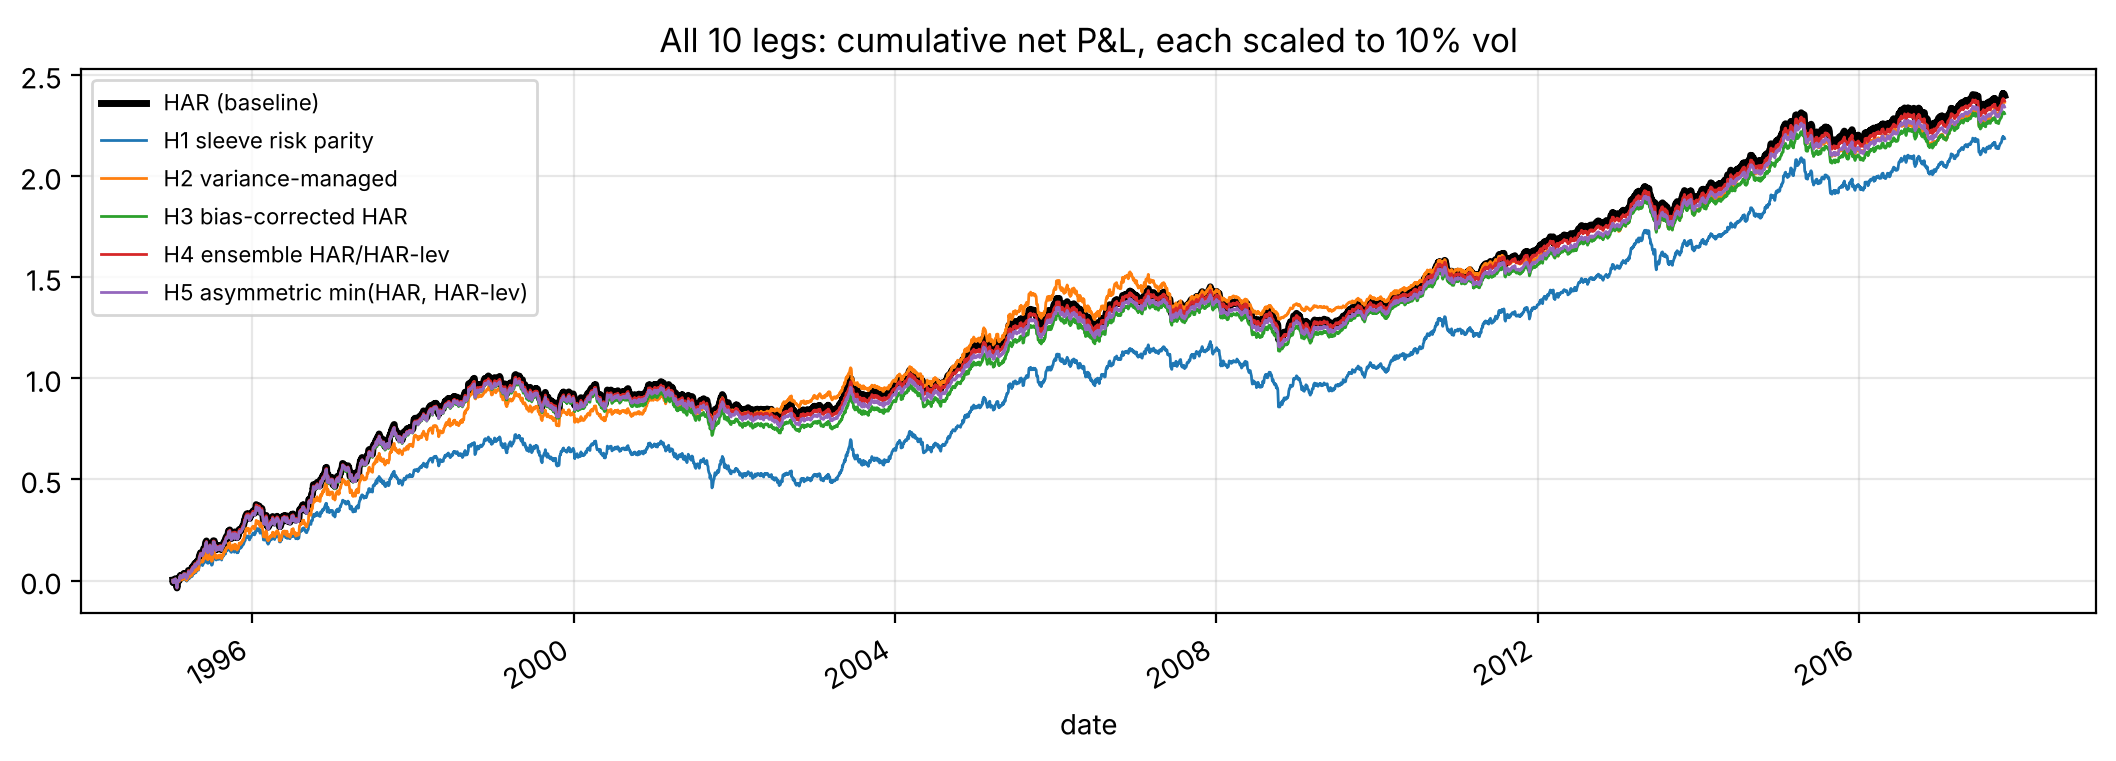

In [10]:
fig, ax = plt.subplots()
for name in VARIANTS:
    pnl = all_pnl(name)
    (pnl / pnl.std() * S.TARGET_VOL / np.sqrt(252)).cumsum().plot(ax=ax, label=name, lw=2.5 if name == BASE else 1, c="k" if name == BASE else None)
ax.set_title("All 10 legs: cumulative net P&L, each scaled to 10% vol")
ax.legend(fontsize=8)
plt.show()

## 8. Conclusion

None of the five pre-registered hypotheses beats the HAR baseline (ALL Sharpe 1.018), and none is adopted.

- **No variant has a higher full-sample Sharpe**: H4 1.007, H2 1.004, H5 0.994, H3 0.980, H1 0.928. All gaps are in the wrong direction.
- **None survives multiple testing**: raw bootstrap p-values are 0.031 to 0.857; the smallest (H5, 0.031) is a *worse* Sharpe than HAR, and after Holm correction every p is at least 0.155.
- **Robustness agrees**: only H2 beats HAR in one sub-period (1995-2006, 1.102 vs 1.045) and it loses in 2007-2017 (0.883 vs 0.992); no variant beats the baseline at doubled costs.
- **Where the ideas failed.** H1 (risk parity with correlation) lowers vol and vol-of-vol but costs return and raises turnover (2.6 to 4.5), because the sleeve multipliers move every day. H2 (variance scaling) raises return and vol together (5.29% / 5.27%, Sharpe unchanged within noise) and raises turnover about five-fold with a deeper bond drawdown (-34%). H3 (walk-forward MZ correction) fits stable equity coefficients (slope 1.4 to 1.7) and bond coefficients near the identity from 1999 (slope 0.91 to 1.02), but the better-calibrated equity forecasts again do not turn into better P&L (EQ Sharpe 0.198 vs 0.227): this repeats the study's finding that forecast accuracy and Sharpe diverge. H4 and H5 mix in the HAR-lev forecast, the one the study already found to score below HAR; mixing it in only dilutes HAR towards it.
- **The DSR criterion is uninformative here**: it equals 1.000 for every strategy, baseline included, so it cannot separate them (see section 2). The decision rests on the bootstrap, Holm and robustness criteria, which agree.

Recommendation: keep the HAR baseline for sizing. The baseline remains fully reproducible (`S.check_baseline`), and "v2" is not created. A caveat: the test has limited power. These are one 23-year sample, so the results show no evidence of improvement, not proof that no improvement exists.